## BÁO CÁO Cuối KỲ - PHÂN TÍCH DỮ LIỆU VÀ AI

## Nhóm thực hiện: Nhóm 11

## MSSV: 24710631

## GV Hướng Dẫn: TS.Ngô Hữu Dũng

## Dataset: Road Traffic Accidents


## “Phân tích và dự đoán mức độ nghiêm trọng của tai nạn giao thông bằng Machine Learning.”

## 1. Tổng quan và chuẩn bị dữ liệu

In [35]:

# 1.1 IMPORT THU VIEN

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import f1_score

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Import thu vien thanh cong!")


Import thu vien thanh cong!


In [36]:

# 1.2. KIEM TRA DUONG DAN DATASET

import os

print(os.listdir('/kaggle/input'))


['datasets']


In [37]:

# 1.3. DOC DU LIEU GOC

df = pd.read_csv(
    '/kaggle/input/datasets/saurabhshahane/road-traffic-accidents/RTA Dataset.csv'
)

print("Doc du lieu thanh cong!")


Doc du lieu thanh cong!


In [38]:

# 1.4. HIEN THI 5 DONG DAU TIEN

df.head()


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [39]:

# 1.5. KICH THUOC DU LIEU

print("So dong:", df.shape[0])
print("So cot:", df.shape[1])


So dong: 12316
So cot: 32


In [40]:

#1.6. THONG TIN DU LIEU

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 1   Day_of_week                  12316 non-null  object
 2   Age_band_of_driver           12316 non-null  object
 3   Sex_of_driver                12316 non-null  object
 4   Educational_level            11575 non-null  object
 5   Vehicle_driver_relation      11737 non-null  object
 6   Driving_experience           11487 non-null  object
 7   Type_of_vehicle              11366 non-null  object
 8   Owner_of_vehicle             11834 non-null  object
 9   Service_year_of_vehicle      8388 non-null   object
 10  Defect_of_vehicle            7889 non-null   object
 11  Area_accident_occured        12077 non-null  object
 12  Lanes_or_Medians             11931 non-null  object
 13  Road_allignment              12

## 2. Khám phá và phân tích dữ liệu (EDA)

In [41]:

# 2.1.KIEM TRA GIA TRI THIEU

missing_data = pd.DataFrame({
    'So luong thieu': df.isnull().sum(),
    'Ty le thieu (%)': (df.isnull().mean() * 100).round(2)
})

missing_data[missing_data['So luong thieu'] > 0].sort_values(
    by='So luong thieu',
    ascending=False
)


,So luong thieu,Ty le thieu (%)
Defect_of_vehicle,4427,35.95
Service_year_of_vehicle,3928,31.89
Work_of_casuality,3198,25.97
Fitness_of_casuality,2635,21.39
Type_of_vehicle,950,7.71
Types_of_Junction,887,7.20
Driving_experience,829,6.73
Educational_level,741,6.02
Vehicle_driver_relation,579,4.70
Owner_of_vehicle,482,3.91


In [42]:

#2.2. KIEM TRA DONG TRUNG LAP

print("So dong trung lap:", df.duplicated().sum())


So dong trung lap: 0


In [43]:
#2.3. SAP XEP THU TU MUC DO NGHIEM TRONG

severity_order = [
    'Slight Injury',
    'Serious Injury',
    'Fatal injury'
]

## 3. Trực quan hóa dữ liệu

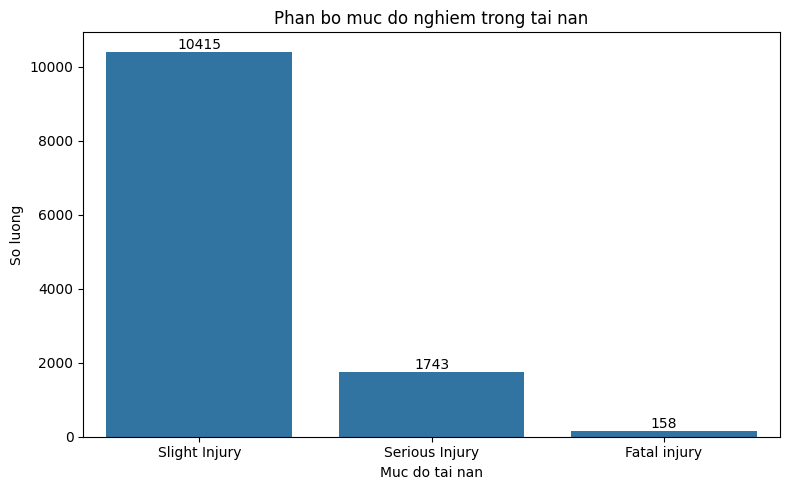

In [44]:
#3.1. PHAN BO MUC DO NGHIEM TRONG TAI NAN

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='Accident_severity',
    order=severity_order
)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Phan bo muc do nghiem trong tai nan')
plt.xlabel('Muc do tai nan')
plt.ylabel('So luong')
plt.tight_layout()
plt.show()

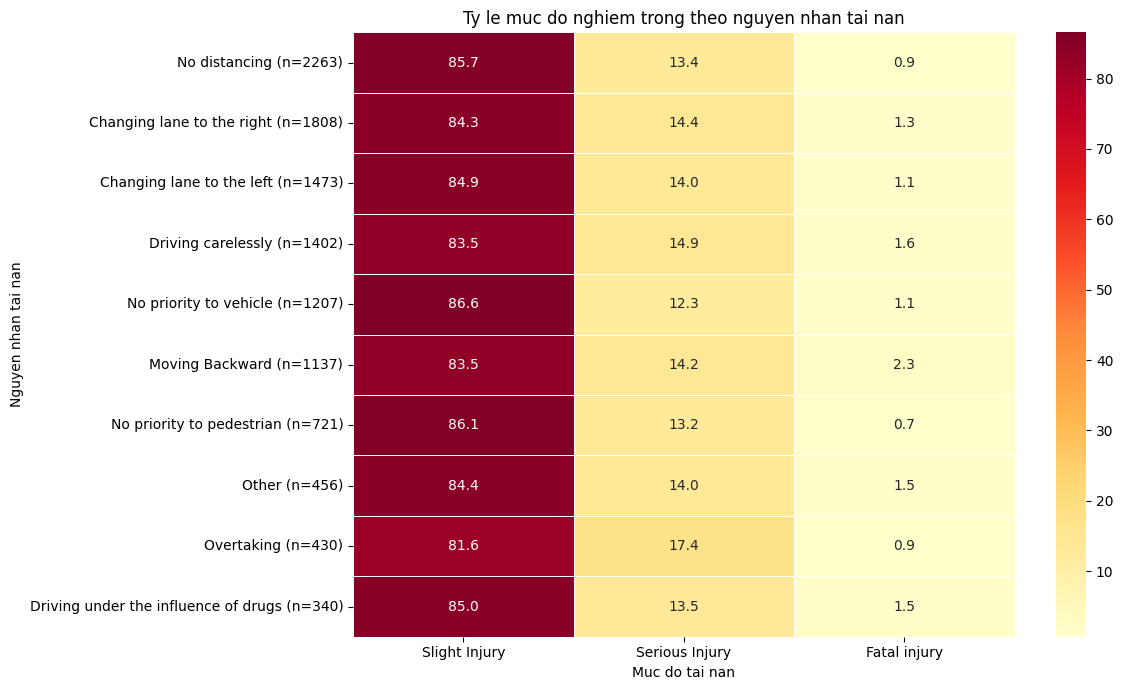

In [45]:
# 3.2. MUC DO TAI NAN THEO NGUYEN NHAN

# Lay 10 nguyen nhan co so vu tai nan nhieu nhat
top_causes = df['Cause_of_accident'].value_counts().head(10).index

cause_data = df[df['Cause_of_accident'].isin(top_causes)]

# Tinh ty le cac muc do tai nan theo tung nguyen nhan
cause_severity = pd.crosstab(
    cause_data['Cause_of_accident'],
    cause_data['Accident_severity'],
    normalize='index'
) * 100

# Sap xep cot va dong
cause_severity = cause_severity.reindex(
    index=top_causes,
    columns=severity_order,
    fill_value=0
)

# Lay so luong vu tai nan cua tung nguyen nhan
cause_counts = cause_data['Cause_of_accident'].value_counts()

# Them so luong vao ten nguyen nhan
cause_severity.index = [
    f'{cause} (n={cause_counts[cause]})'
    for cause in cause_severity.index
]

# Ve Heatmap
plt.figure(figsize=(12, 7))

sns.heatmap(
    cause_severity,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Ty le muc do nghiem trong theo nguyen nhan tai nan')
plt.xlabel('Muc do tai nan')
plt.ylabel('Nguyen nhan tai nan')
plt.tight_layout()
plt.show()

In [46]:
# 3.3. TAO COT GIO TU THOI GIAN TAI NAN

df['Hour'] = pd.to_datetime(
    df['Time'],
    format='%H:%M:%S',
    errors='coerce'
).dt.hour

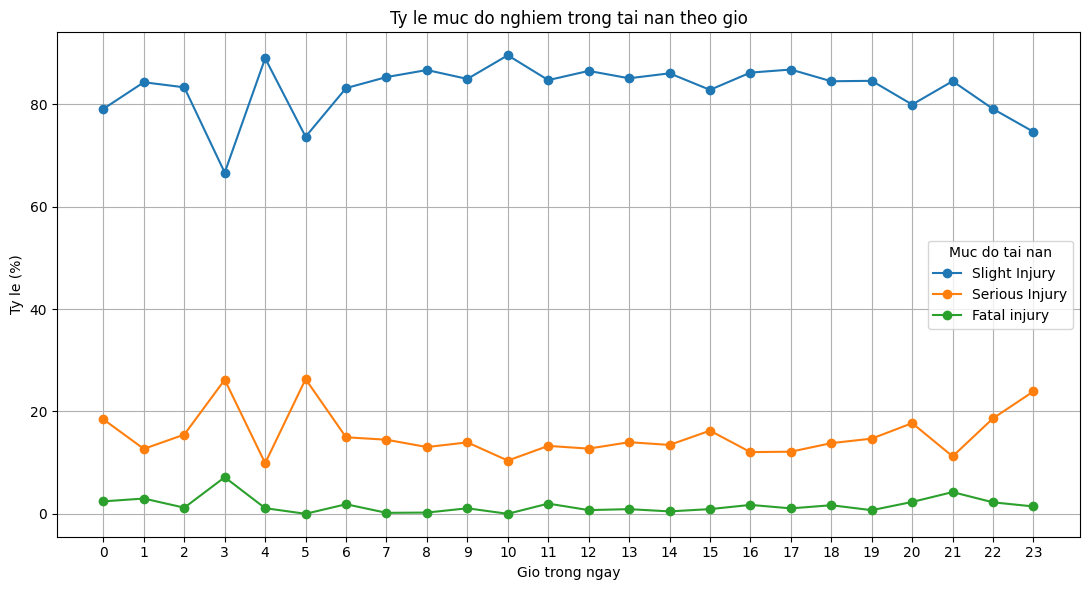

In [47]:
# 3.4. MUC DO TAI NAN THEO GIO

hour_severity = pd.crosstab(
    df['Hour'],
    df['Accident_severity'],
    normalize='index'
) * 100

hour_severity = hour_severity.reindex(
    columns=severity_order,
    fill_value=0
)

hour_severity.plot(
    kind='line',
    marker='o',
    figsize=(11, 6)
)

plt.title('Ty le muc do nghiem trong tai nan theo gio')
plt.xlabel('Gio trong ngay')
plt.ylabel('Ty le (%)')
plt.xticks(range(24))
plt.legend(title='Muc do tai nan')
plt.grid(True)
plt.tight_layout()
plt.show()

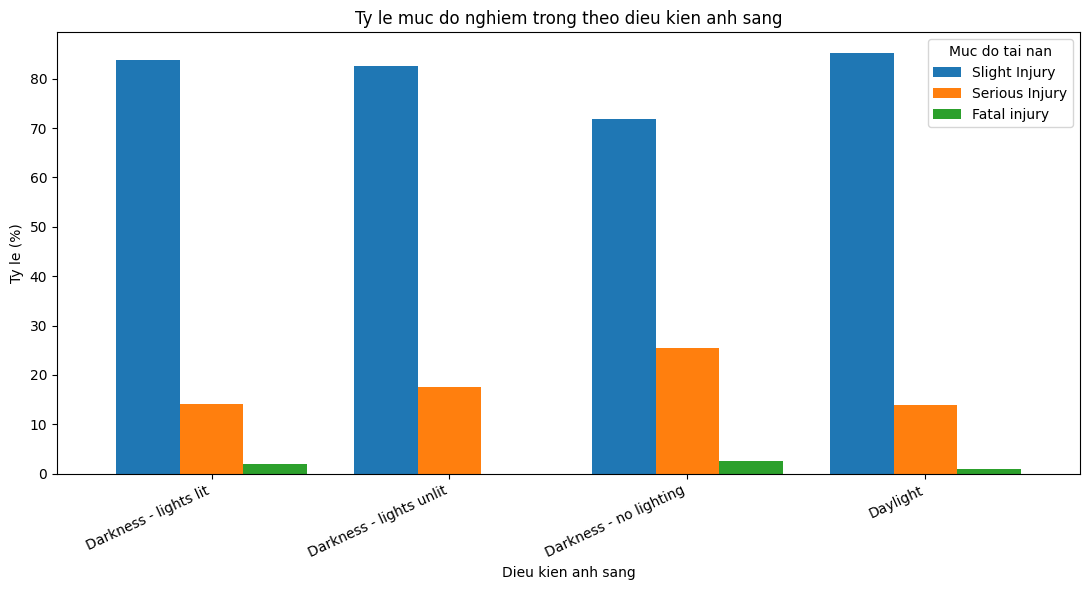

In [48]:
# 3.5. MUC DO TAI NAN THEO DIEU KIEN ANH SANG

light_severity = pd.crosstab(
    df['Light_conditions'],
    df['Accident_severity'],
    normalize='index'
) * 100

light_severity = light_severity.reindex(
    columns=severity_order,
    fill_value=0
)

light_severity.plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title('Ty le muc do nghiem trong theo dieu kien anh sang')
plt.xlabel('Dieu kien anh sang')
plt.ylabel('Ty le (%)')
plt.xticks(rotation=25, ha='right')
plt.legend(title='Muc do tai nan')
plt.tight_layout()
plt.show()

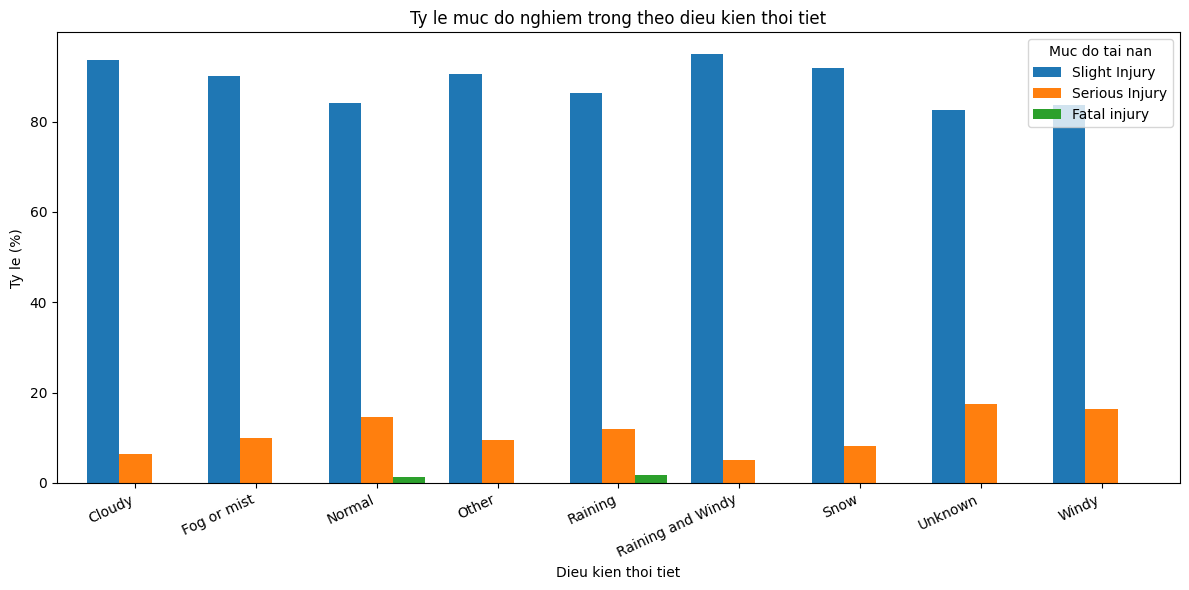

In [49]:
# 3.6. MUC DO TAI NAN THEO DIEU KIEN THOI TIET

weather_severity = pd.crosstab(
    df['Weather_conditions'],
    df['Accident_severity'],
    normalize='index'
) * 100

weather_severity = weather_severity.reindex(
    columns=severity_order,
    fill_value=0
)

weather_severity.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Ty le muc do nghiem trong theo dieu kien thoi tiet')
plt.xlabel('Dieu kien thoi tiet')
plt.ylabel('Ty le (%)')
plt.xticks(rotation=25, ha='right')
plt.legend(title='Muc do tai nan')
plt.tight_layout()
plt.show()

## 4. Tiền xử lý dữ liệu

In [50]:
# 4.1. KIEM TRA CAC GIA TRI TRONG CAC COT PHAN LOAI

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))


--- Time ---
Time
15:30:00    120
17:10:00    110
18:30:00    103
11:30:00     99
17:00:00     98
16:00:00     97
18:00:00     95
19:00:00     94
17:50:00     88
17:25:00     87
16:30:00     87
20:30:00     86
15:00:00     83
12:00:00     81
15:20:00     79
Name: count, dtype: int64

--- Day_of_week ---
Day_of_week
Friday       2041
Thursday     1851
Wednesday    1840
Tuesday      1770
Monday       1681
Saturday     1666
Sunday       1467
Name: count, dtype: int64

--- Age_band_of_driver ---
Age_band_of_driver
18-30       4271
31-50       4087
Over 51     1585
Unknown     1548
Under 18     825
Name: count, dtype: int64

--- Sex_of_driver ---
Sex_of_driver
Male       11437
Female       701
Unknown      178
Name: count, dtype: int64

--- Educational_level ---
Educational_level
Junior high school    7619
Elementary school     2163
High school           1110
NaN                    741
Above high school      362
Writing & reading      176
Unknown                100
Illiterate              

In [51]:
#4.2. LAM SACH DU LIEU DANG CHU

# Xoa khoang trang thua
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Chuan hoa cac gia tri Unknown
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].replace(
        to_replace=r'(?i)^unknown$',
        value='Unknown',
        regex=True
    )

# Thay gia tri thieu bang Unknown
df = df.fillna('Unknown')

print("Da lam sach du lieu!")
print("\nSo luong gia tri thieu sau khi lam sach:")
print(df.isnull().sum().sum())

print("\nKich thuoc du lieu:")
print(df.shape)

Da lam sach du lieu!

So luong gia tri thieu sau khi lam sach:
0

Kich thuoc du lieu:
(12316, 33)


In [52]:
#4.3. CHON CAC COT DAU VAO VA BIEN MUC TIEU

feature_cols = [
    'Hour',
    'Day_of_week',
    'Age_band_of_driver',
    'Sex_of_driver',
    'Educational_level',
    'Vehicle_driver_relation',
    'Driving_experience',
    'Type_of_vehicle',
    'Owner_of_vehicle',
    'Service_year_of_vehicle',
    'Defect_of_vehicle',
    'Area_accident_occured',
    'Lanes_or_Medians',
    'Road_allignment',
    'Types_of_Junction',
    'Road_surface_type',
    'Road_surface_conditions',
    'Light_conditions',
    'Weather_conditions',
    'Type_of_collision',
    'Vehicle_movement',
    'Pedestrian_movement',
    'Cause_of_accident'
]

# Tao X va y
X = df[feature_cols]
y = df['Accident_severity']

print("So dong du lieu:", X.shape[0])
print("So cot dau vao:", X.shape[1])

print("\nPhan bo bien muc tieu:")
print(y.value_counts())

print("\nTy le phan tram:")
print((y.value_counts(normalize=True) * 100).round(2))

So dong du lieu: 12316
So cot dau vao: 23

Phan bo bien muc tieu:
Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64

Ty le phan tram:
Accident_severity
Slight Injury     84.56
Serious Injury    14.15
Fatal injury       1.28
Name: proportion, dtype: float64


In [53]:
# 4.4. CHIA DU LIEU TRAIN VA TEST

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("So dong tap Train:", X_train.shape[0])
print("So dong tap Test:", X_test.shape[0])

print("\nTy le cac nhom trong tap Train:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTy le cac nhom trong tap Test:")
print((y_test.value_counts(normalize=True) * 100).round(2))

So dong tap Train: 9852
So dong tap Test: 2464

Ty le cac nhom trong tap Train:
Accident_severity
Slight Injury     84.56
Serious Injury    14.15
Fatal injury       1.29
Name: proportion, dtype: float64

Ty le cac nhom trong tap Test:
Accident_severity
Slight Injury     84.58
Serious Injury    14.16
Fatal injury       1.26
Name: proportion, dtype: float64


In [54]:
# 4.5. XAC DINH CAC COT PHAN LOAI

categorical_cols = X_train.select_dtypes(
    include='object'
).columns.tolist()

# TAO BO MA HOA ONE-HOT
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

# HUAN LUYEN BO MA HOA TREN TAP TRAIN
X_train_encoded = preprocessor.fit_transform(X_train)

# MA HOA TAP TEST
X_test_encoded = preprocessor.transform(X_test)

print("So cot truoc khi ma hoa:", X_train.shape[1])
print("So cot sau khi ma hoa:", X_train_encoded.shape[1])

print("Kich thuoc X_train:", X_train_encoded.shape)
print("Kich thuoc X_test:", X_test_encoded.shape)

So cot truoc khi ma hoa: 23
So cot sau khi ma hoa: 180
Kich thuoc X_train: (9852, 180)
Kich thuoc X_test: (2464, 180)


## 5. Xây dựng và huấn luyện mô hình

# 5.1. KHỞI TẠO CÁC MÔ HÌNH MACHINE LEARNING

In [55]:
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        max_iter=3000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

# Chuan hoa du lieu cho Logistic Regression
scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

# Huan luyen cac mo hinh
for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
    else:
        model.fit(X_train_encoded, y_train)

# 5.2. Phân tích hệ số và độ quan trọng của thuộc tính

In [56]:
feature_names = preprocessor.get_feature_names_out()

for i, class_name in enumerate(models['Logistic Regression'].classes_):

    coef_df = pd.DataFrame({
        'Thuoc tinh': feature_names,
        'He so': models['Logistic Regression'].coef_[i]
    })

    print("\nMUC DO:", class_name)

    print(
        coef_df.sort_values(
            by='He so',
            key=abs,
            ascending=False
        ).head(10).to_string(index=False)
    )


MUC DO: Fatal injury
                                                                                             Thuoc tinh     He so
                                                         cat__Area_accident_occured_Outside rural areas -0.653107
                                                                    cat__Road_surface_type_Gravel roads -0.618881
                                                                        cat__Weather_conditions_Unknown -0.603173
                                                                          cat__Weather_conditions_Other -0.578705
                                                                          cat__Weather_conditions_Windy -0.474560
                                                                         cat__Road_surface_type_Unknown -0.472586
                                                              cat__Area_accident_occured_Hospital areas -0.442076
                                                                  

Nhận xét:
- Hệ số dương: làm tăng điểm dự đoán của mức độ tai nạn tương ứng.
- Hệ số âm: làm giảm điểm dự đoán của mức độ tai nạn tương ứng.
- Một số thuộc tính có hệ số nổi bật: khu vực xảy ra tai nạn, điều kiện thời tiết, loại mặt đường, loại phương tiện và kinh nghiệm lái xe.
- Các thuộc tính này có đóng góp đáng chú ý trong quá trình phân loại của mô hình.
- Hệ số thể hiện chiều hướng đóng góp trong mô hình, không khẳng định đó là nguyên nhân trực tiếp gây tai nạn.

In [57]:
for name in ['Decision Tree', 'Random Forest']:

    importance_df = pd.DataFrame({
        'Thuoc tinh': feature_names,
        'Do quan trong': models[name].feature_importances_
    })

    print("\n", name)

    print(
        importance_df.sort_values(
            by='Do quan trong',
            ascending=False
        ).head(10).to_string(index=False)
    )


 Decision Tree
                                   Thuoc tinh  Do quan trong
                              remainder__Hour       0.094827
         cat__Type_of_vehicle_Lorry (41?100Q)       0.024714
             cat__Area_accident_occured_Other       0.022315
               cat__Driving_experience_5-10yr       0.020850
              cat__Types_of_Junction_Crossing       0.020793
                      cat__Day_of_week_Friday       0.020613
               cat__Types_of_Junction_Y Shape       0.019306
cat__Cause_of_accident_No priority to vehicle       0.018129
      cat__Area_accident_occured_Office areas       0.017516
                   cat__Day_of_week_Wednesday       0.017137

 Random Forest
                                                            Thuoc tinh  Do quan trong
                                                       remainder__Hour       0.069128
                                         cat__Age_band_of_driver_18-30       0.015718
                                       

Decision Tree:
- Giờ xảy ra tai nạn là thuộc tính quan trọng nhất.
- Các thuộc tính tiếp theo có giá trị thấp hơn và phân bố khá gần nhau.
Random Forest:
- Giờ xảy ra tai nạn tiếp tục là thuộc tính quan trọng nhất.
- Các thuộc tính còn lại chủ yếu liên quan đến tuổi người lái xe, loại giao lộ và hướng di chuyển của phương tiện.
- Cả Decision Tree và Random Forest đều cho thấy giờ xảy ra tai nạn là thuộc tính có độ quan trọng cao nhất.
Tuy nhiên, những thuộc tính đứng sau có sự khác nhau giữa hai mô hình.
Điều này cho thấy mỗi thuật toán có cách đánh giá và sử dụng thuộc tính khác nhau trong quá trình dự đoán.

## 6. Đánh giá mô hình

In [58]:
#6.1. DU DOAN VA DANH GIA CAC MO HINH

results = []

for name, model in models.items():

    # Chon du lieu phu hop voi tung mo hinh
    if name == 'Logistic Regression':
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test_encoded

    # Du doan
    y_pred = model.predict(X_test_model)

    # Tinh cac chi so danh gia
    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Macro F1': macro_f1,
        'Weighted F1': weighted_f1
    })

# Tao bang ket qua
results_df = pd.DataFrame(results)

print("BANG SO SANH CAC MO HINH:")
display(results_df.round(4))

BANG SO SANH CAC MO HINH:


,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.4635,0.2971,0.5536
1,Decision Tree,0.7240,0.3576,0.7335
2,Random Forest,0.8458,0.3055,0.7751


In [59]:
# 6.2. BAO CAO CHI TIET CAC MO HINH

for name, model in models.items():

    if name == 'Logistic Regression':
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test_encoded

    y_pred = model.predict(X_test_model)

    print("\nMO HINH:", name)
    print(classification_report(y_test, y_pred, zero_division=0))


MO HINH: Logistic Regression
                precision    recall  f1-score   support

  Fatal injury       0.02      0.29      0.03        31
Serious Injury       0.17      0.41      0.24       349
 Slight Injury       0.86      0.48      0.61      2084

      accuracy                           0.46      2464
     macro avg       0.35      0.39      0.30      2464
  weighted avg       0.76      0.46      0.55      2464


MO HINH: Decision Tree
                precision    recall  f1-score   support

  Fatal injury       0.05      0.10      0.07        31
Serious Injury       0.16      0.17      0.17       349
 Slight Injury       0.85      0.83      0.84      2084

      accuracy                           0.72      2464
     macro avg       0.35      0.37      0.36      2464
  weighted avg       0.74      0.72      0.73      2464


MO HINH: Random Forest
                precision    recall  f1-score   support

  Fatal injury       0.00      0.00      0.00        31
Serious Injury     

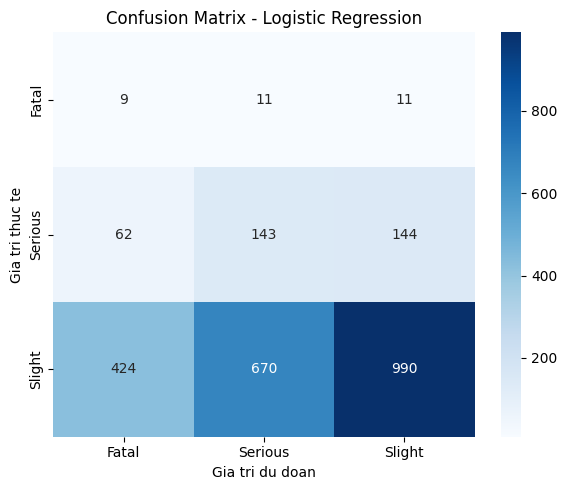

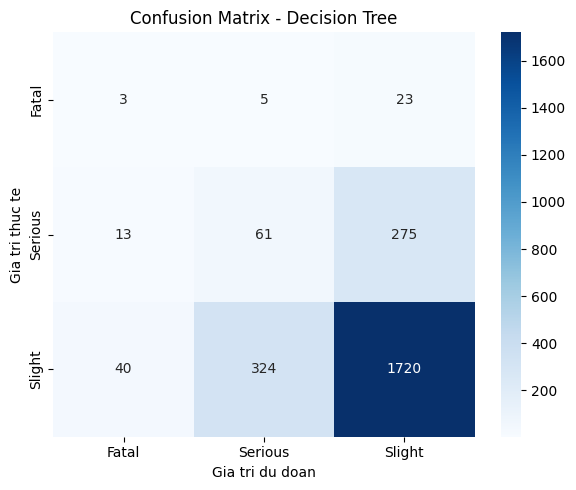

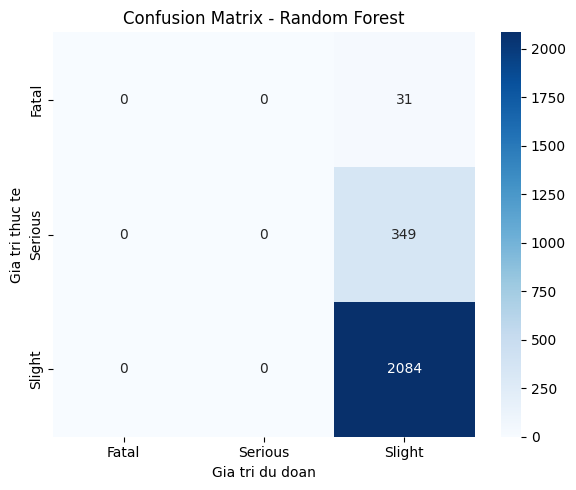

In [60]:
# 6.3. VE MA TRAN NHAM LAN CUA 3 MO HINH

for name, model in models.items():

    if name == 'Logistic Regression':
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test_encoded

    y_pred = model.predict(X_test_model)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=['Fatal injury', 'Serious Injury', 'Slight Injury']
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Fatal', 'Serious', 'Slight'],
        yticklabels=['Fatal', 'Serious', 'Slight']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Gia tri du doan')
    plt.ylabel('Gia tri thuc te')
    plt.tight_layout()
    plt.show()

## 7. Tối ưu mô hình

In [61]:
# 7.1. Tối ưu Decision Tree bằng GridSearchCV và Cross-Validation
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 5, 10]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),
    param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train_encoded, y_train)

best_model = grid_search.best_estimator_

print("Tham số tốt nhất:", grid_search.best_params_)
print("Macro F1 tốt nhất:", grid_search.best_score_)

Tham số tốt nhất: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Macro F1 tốt nhất: 0.3471048177525111


In [62]:
# 7.2. Đánh giá Decision Tree sau tối ưu
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred_best = best_model.predict(X_test_encoded)

print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Macro F1:", f1_score(y_test, y_pred_best, average='macro'))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Accuracy: 0.724025974025974
Macro F1: 0.35755626118156364

Classification Report:
                precision    recall  f1-score   support

  Fatal injury       0.05      0.10      0.07        31
Serious Injury       0.16      0.17      0.17       349
 Slight Injury       0.85      0.83      0.84      2084

      accuracy                           0.72      2464
     macro avg       0.35      0.37      0.36      2464
  weighted avg       0.74      0.72      0.73      2464



## 8. Tổng kết kết quả

# 8.1. Tổng hợp kết quả thực nghiệm

Trong quá trình thực nghiệm, nhóm đã sử dụng ba thuật toán Machine Learning để xây dựng mô hình dự đoán mức độ nghiêm trọng của tai nạn giao thông, bao gồm Logistic Regression, Decision Tree và Random Forest.

Kết quả đánh giá trên tập kiểm tra gồm 2.464 mẫu:

| Mô hình | Accuracy | Macro F1 |
|---|---:|---:|
| Logistic Regression | 46% | 0,30 |
| Decision Tree | 72% | **0,36** |
| Random Forest | **85%** | 0,31 |

Qua kết quả trên, có thể nhận thấy:

- **Logistic Regression:** Đạt Accuracy 46%, Macro F1 0,30. Mô hình có khả năng nhận diện một số trường hợp tai nạn nghiêm trọng nhưng kết quả dự đoán tổng thể còn hạn chế.
- **Decision Tree:** Đạt Accuracy khoảng 72%, Macro F1 khoảng 0,36. Đây là mô hình có Macro F1 cao nhất trong ba thuật toán được thử nghiệm.
- **Random Forest:** Đạt Accuracy khoảng 85%, nhưng Macro F1 chỉ đạt 0,31. Mô hình chủ yếu dự đoán các trường hợp Slight Injury và không nhận diện được hai nhóm Serious Injury và Fatal Injury trong tập kiểm tra.

Nhóm tiếp tục sử dụng GridSearchCV kết hợp Cross-Validation để tối ưu Decision Tree. Kết quả lựa chọn bộ tham số `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1`, với Macro F1 trung bình đạt 0,3471.

Sau tối ưu, mô hình đạt Accuracy 72,40% và Macro F1 0,3576 trên tập kiểm tra. Kết quả gần như không thay đổi so với mô hình Decision Tree ban đầu.

# 8.2. Hạn chế của mô hình

Mặc dù đã xây dựng và đánh giá được ba mô hình dự đoán, đề tài vẫn còn một số hạn chế:

- **Dữ liệu mất cân bằng:** Số lượng mẫu Slight Injury chiếm khoảng 84,56%, trong khi Fatal Injury chỉ chiếm khoảng 1,28%. Điều này khiến mô hình khó học được đặc điểm của nhóm tai nạn nghiêm trọng.
- **Khả năng nhận diện nhóm thiểu số còn thấp:** Các mô hình chưa dự đoán tốt hai nhóm Serious Injury và Fatal Injury, đặc biệt là Random Forest.
- **Kết quả tối ưu chưa cải thiện đáng kể:** Việc sử dụng GridSearchCV chưa giúp Decision Tree nâng cao rõ rệt hiệu quả dự đoán.
- **Phạm vi dữ liệu còn giới hạn:** Bộ dữ liệu được thu thập từ các vụ tai nạn tại thành phố Addis Ababa, Ethiopia trong giai đoạn 2017–2020. Vì vậy, kết quả chưa thể đại diện cho tình hình tai nạn giao thông ở các khu vực khác.

# 8.3. Kết luận và hướng phát triển

Đề tài đã thực hiện quy trình phân tích dữ liệu và ứng dụng Machine Learning để dự đoán mức độ nghiêm trọng của tai nạn giao thông. Nhóm đã tiến hành khám phá dữ liệu, trực quan hóa, xử lý dữ liệu thiếu, mã hóa các thuộc tính phân loại, chia tập dữ liệu và xây dựng ba mô hình Logistic Regression, Decision Tree và Random Forest.

Thông qua quá trình đánh giá, Decision Tree được lựa chọn làm mô hình phù hợp nhất trong ba thuật toán đã thử nghiệm vì đạt Macro F1 cao nhất, khoảng 0,36. Tuy nhiên, hiệu quả nhận diện các trường hợp tai nạn nghiêm trọng và tử vong vẫn còn thấp do sự mất cân bằng giữa các lớp dữ liệu.

Trong tương lai, đề tài có thể được phát triển bằng cách bổ sung dữ liệu tai nạn từ nhiều khu vực và thời điểm khác nhau, thử nghiệm các phương pháp xử lý dữ liệu mất cân bằng, đồng thời nghiên cứu thêm các thuật toán và phương pháp tối ưu nhằm cải thiện khả năng nhận diện những vụ tai nạn có mức độ nghiêm trọng cao.